In [122]:
from pathlib import Path
import sys
import pandas as pd


import seaborn as sns
import matplotlib.pyplot as plt

# Find the repo root whether the notebook is run from notebooks/ or the repo itself, so dgvt_styles imports
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dgvt_styles').is_dir())
sys.path.insert(0, str(ROOT))
from dgvt_styles.features import add_training_flag, add_strokes_gained

DATA_DIR = Path('..') / 'data'
FIGURES_DIR = Path('..') / 'figures'
%matplotlib inline

In [123]:
# Load processed data for each year, add year column and concatenate into a single DataFrame
events_dataframes = []
holes_dataframes = []
hole_scores_dataframes = []
rounds_dataframes = []

for year in range(2019, 2027):
    processed_dir = DATA_DIR / str(year) / 'processed'

    # Events
    events = pd.read_csv(processed_dir / 'events.csv')
    events['year'] = year

    # Hole Scores
    # player_key is a PDGA number or 'name:<name>'; read it as str so the same player isn't split into int and str keys
    hole_scores = pd.read_csv(processed_dir / 'hole_scores.csv', dtype={'player_key': str})
    hole_scores['year'] = year

    # Holes
    holes = pd.read_csv(processed_dir / 'holes.csv')
    holes['year'] = year

    # Rounds
    rounds = pd.read_csv(processed_dir / 'rounds.csv', dtype={'player_key': str})
    rounds['year'] = year

    # Append DataFrames to the respective lists
    events_dataframes.append(events)
    hole_scores_dataframes.append(hole_scores)
    holes_dataframes.append(holes)
    rounds_dataframes.append(rounds)

# Concatenate all DataFrames into 4 single DataFrame
events_df = pd.concat(events_dataframes, ignore_index=True)
hole_scores_df = pd.concat(hole_scores_dataframes, ignore_index=True)
holes_df = pd.concat(holes_dataframes, ignore_index=True)
rounds_df = pd.concat(rounds_dataframes, ignore_index=True)

# Feature Generation

Generating the following hole x player x round level features:
1. strokes gained: the field's average score on a hole minus the player's score
- Compute the average hole score for every player that played that hole in that specific round of that tournament

2. style-adjusted: version that subtracts the player's own average so it shows where they gain and lose strokes instead of how many

3. hole types: short, medium, or long within each par

The analysis feature table uses 2020-2026 only. The 2019 rows remain in the combined audit tables because only 2 of 8 events have hole-by-hole scores.

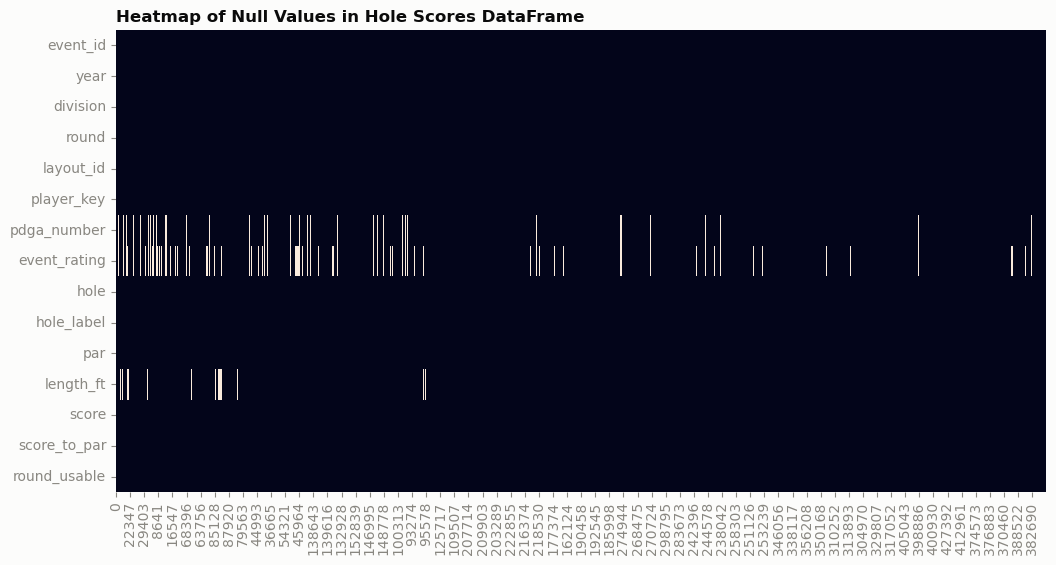

In [124]:
# visualize heatmap of null values in the hole_scores_df DataFrame
plt.figure(figsize=(12, 6))
sns.heatmap(hole_scores_df.sort_values('year').T.isnull(), cbar=False)
plt.title('Heatmap of Null Values in Hole Scores DataFrame')
plt.show()

It looks like hole length is missing from a handful of early courses, and one later, but not many. There are quite a few people who either don't have a PDGA number and subsequently don't have an event_rating.

In [125]:
# % of null rows in each column of the hole_scores_df DataFrame
null_percentage = hole_scores_df.isnull().mean() * 100
round(null_percentage, 2).sort_values(ascending=False)

event_rating    9.45
pdga_number     4.18
length_ft       1.39
event_id        0.00
year            0.00
division        0.00
round           0.00
layout_id       0.00
player_key      0.00
hole            0.00
hole_label      0.00
par             0.00
score           0.00
score_to_par    0.00
round_usable    0.00
dtype: float64

In [126]:
## Rounds with no event-time rating
# These players still count toward the field average (strokes gained) but are left out of training data
# (profiles, clustering, models). Same rule as the Kingdom Open notebook: dgvt_styles.features.add_training_flag
rounds_df = add_training_flag(rounds_df)
hole_scores_df = add_training_flag(hole_scores_df)

def rating_status(df):
    status = pd.Series('PDGA number, unrated at the time', index=df.index)
    status[df['in_training']] = 'rated'
    status[~df['has_pdga_number']] = 'no PDGA number'
    return status

status_counts = pd.DataFrame({
    'all rounds': rating_status(rounds_df).value_counts(),
    'usable rounds': rating_status(rounds_df[rounds_df['usable']]).value_counts(),
})
display(status_counts)

# Check: unrated rounds by players with a PDGA number come before their first rated round (or they're never rated)
first_rated = rounds_df[rounds_df['in_training']].groupby('player_key')['round_date'].min()
unrated = rounds_df[rounds_df['has_pdga_number'] & ~rounds_df['in_training']]
later_rated = unrated['round_date'] < unrated['player_key'].map(first_rated)
never_rated = unrated['player_key'].map(first_rated).isna()
assert (later_rated | never_rated).all()
print(f'Unrated rounds with a PDGA number: {later_rated.sum()} before the player\'s first rated round, '
      f'{never_rated.sum()} by players never rated in this data')

,all rounds,usable rounds
rated,23085,21587
"PDGA number, unrated at the time",1333,1256
no PDGA number,1222,995


Unrated rounds with a PDGA number: 1037 before the player's first rated round, 296 by players never rated in this data


# Feature Generation

Generating the following hole x player x round level features:
1. strokes gained: the field's average score on a hole minus the player's score
- Compute the average hole score for every player that played that hole in that specific round of that tournament

2. style-adjusted: version that subtracts the player's own average so it shows where they gain and lose strokes instead of how many

3. hole types: short, medium, or long within each par

In [127]:
## 1. Strokes gained
# Shared helper (dgvt_styles.features.add_strokes_gained): keeps usable rounds (every hole scored, holes add up to
# the round total) and compares each score to everyone who played the same hole on the same layout in the same round,
# across divisions. Players with no PDGA number or no rating are part of the field.
features_df = add_strokes_gained(hole_scores_df)
print(f"{(~features_df['in_training']).sum():,} of {len(features_df):,} hole scores are in the field but not in training data")

features_df[['field_avg', 'field_n', 'strokes_gained']].describe()

39,996 of 425,862 hole scores are in the field but not in training data


,field_avg,field_n,strokes_gained
count,425862.000000,425862.000000,4.258620e+05
mean,3.646850,85.780168,3.670659e-18
std,0.796475,42.009973,8.633041e-01
min,2.236842,2.000000,-1.241176e+01
25%,3.090909,50.000000,-4.583333e-01
50%,3.397849,87.000000,1.014493e-01
75%,4.047059,127.000000,5.555556e-01
max,10.000000,161.000000,5.500000e+00


In [128]:
## 2. Style-adjusted strokes gained
# Subtract the player's average strokes gained per hole in that round. This removes skill and
# that day's form, leaving only where in the round they gained or lost strokes.
# Using the round (not the player's career average) also keeps 2019-2023 and 2024-2026 separate.
round_keys = ['event_id', 'round', 'layout_id', 'player_key']
features_df['round_sg_avg'] = features_df.groupby(round_keys)['strokes_gained'].transform('mean')
features_df['sg_style_adj'] = features_df['strokes_gained'] - features_df['round_sg_avg']

# Check: style-adjusted strokes gained sums to 0 within every player-round
assert features_df.groupby(round_keys)['sg_style_adj'].sum().abs().max() < 1e-9

features_df[['strokes_gained', 'round_sg_avg', 'sg_style_adj']].describe()

,strokes_gained,round_sg_avg,sg_style_adj
count,4.258620e+05,4.258620e+05,4.258620e+05
mean,3.670659e-18,3.236854e-18,1.042801e-19
std,8.633041e-01,3.871722e-01,7.716162e-01
min,-1.241176e+01,-4.683007e+00,-9.263158e+00
25%,-4.583333e-01,-1.881481e-01,-4.202899e-01
50%,1.014493e-01,4.465213e-02,6.645898e-02
75%,5.555556e-01,2.465278e-01,5.076389e-01
max,5.500000e+00,1.625000e+00,3.875000e+00


In [129]:
## 3. Hole types: short / medium / long within each par
# Cutoffs are terciles of length within each par, computed over distinct layout x hole combos
# so courses that hosted many events don't pull the cutoffs toward their holes
unique_holes = features_df.drop_duplicates(['layout_id', 'hole'])[['layout_id', 'hole', 'par', 'length_ft']].copy()
unique_holes['hole_type'] = (
    unique_holes.groupby('par')['length_ft']
    .transform(lambda lengths: pd.qcut(lengths, 3, labels=['short', 'medium', 'long']))
)

# Holes with no length_ft (about 1.4% of scores) are left without a hole type
features_df = features_df.merge(unique_holes[['layout_id', 'hole', 'hole_type']], on=['layout_id', 'hole'], how='left')
features_df['hole_type'] = pd.Categorical(features_df['hole_type'], categories=['short', 'medium', 'long'], ordered=True)

# Length cutoffs for each par x hole type
unique_holes.groupby(['par', 'hole_type'], observed=True)['length_ft'].agg(['count', 'min', 'max'])

count    min     max
par hole_type                      
3   short       1014   72.0   225.0
    medium       964  226.0   294.0
    long         987  295.0   675.0
4   short        411  135.0   394.0
    medium       412  395.0   513.0
    long         411  515.0   856.0
5   short         59  337.0   620.0
    medium        57  633.0   795.0
    long          59  830.0  1345.0

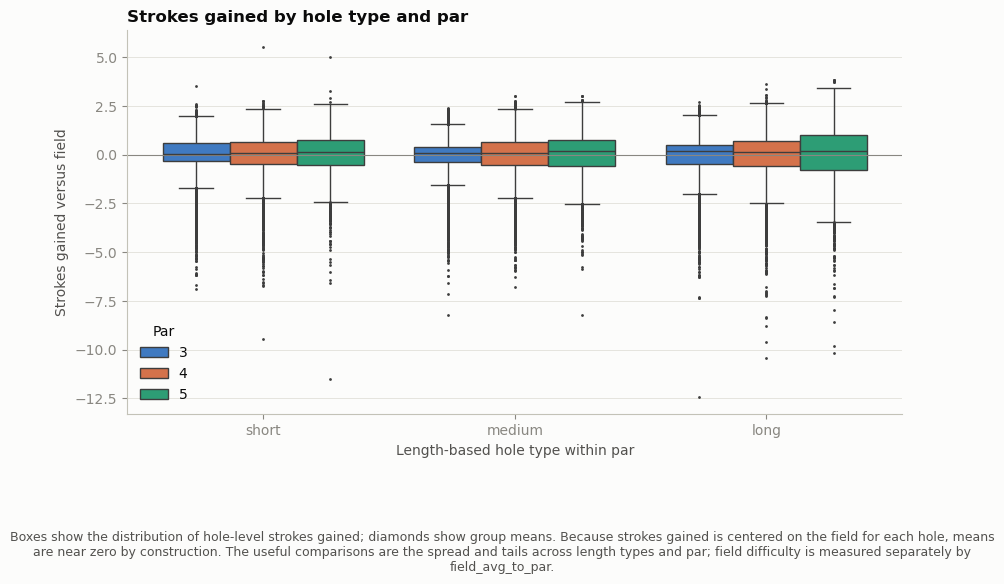

par          3    4    5
hole_type               
short      0.0 -0.0  0.0
medium    -0.0  0.0  0.0
long       0.0  0.0  0.0


In [151]:
## Strokes gained by length-based hole type
# General project-level comparison of strokes gained across short, medium, and long holes.
# Par is shown separately because hole length and scoring scale differ by par.
hole_type_order = ['short', 'medium', 'long']
plot_features = features_df.dropna(subset=['hole_type']).copy()
plot_features['hole_type'] = pd.Categorical(
    plot_features['hole_type'], categories=hole_type_order, ordered=True)

fig, ax = plt.subplots(figsize=(10, 6.4))
fig.subplots_adjust(bottom=0.28)
sns.boxplot(
    data=plot_features,
    x='hole_type',
    y='strokes_gained',
    hue='par',
    order=hole_type_order,
    palette=['#2a78d6', '#eb6834', '#1baf7a'],
    fliersize=1,
    ax=ax,
)
means = (plot_features.groupby(['hole_type', 'par'], observed=True)['strokes_gained']
         .mean()
         .reset_index())
sns.scatterplot(
    data=means,
    x='hole_type',
    y='strokes_gained',
    hue='par',
    hue_order=sorted(plot_features['par'].dropna().unique()),
    palette=['#2a78d6', '#eb6834', '#1baf7a'],
    marker='D',
    s=42,
    edgecolor='white',
    linewidth=0.8,
    legend=False,
    ax=ax,
)
ax.axhline(0, color='#898781', linewidth=0.8)
ax.set(
    xlabel='Length-based hole type within par',
    ylabel='Strokes gained versus field',
    title='Strokes gained by hole type and par',
)
ax.legend(title='Par', frameon=False)
fig.text(
    0.5,
    0.03,
    'Boxes show the distribution of hole-level strokes gained; diamonds show group means. '
    'Because strokes gained is centered on the field for each hole, means are near zero by construction. '
    'The useful comparisons are the spread and tails across length types and par; field difficulty is measured separately by field_avg_to_par.',
    ha='center',
    va='bottom',
    wrap=True,
    color='#52514e',
    fontsize=9,
)
plt.show()

print(means.pivot(index='hole_type', columns='par', values='strokes_gained').round(3))

In [ ]:
fig.savefig(ROOT / 'Documents' / 'figures' / 'eda_strokes_gained_by_hole_type.png', dpi=180, bbox_inches='tight')

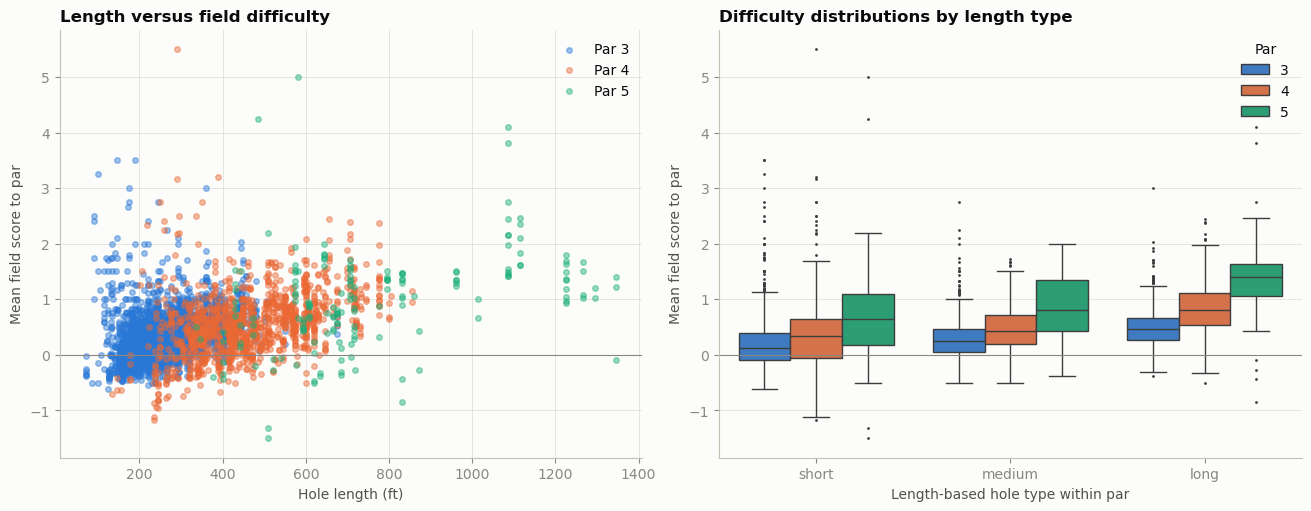

par           
3    length_ft    0.293497
4    length_ft    0.398925
5    length_ft    0.373639
Name: length_difficulty_correlation, dtype: float64


In [131]:
## Does length explain field difficulty
# Summarize repeated observations of each layout hole across rounds, then keep length and
# field difficulty as separate measurements while exploring their relationship.
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dgvt_styles').is_dir())
difficulty_features = pd.read_csv(
    root / 'dgvt_styles' / 'build_hole_features' / 'output' / 'hole_features.csv',
    dtype={'player_key': str},
)
hole_difficulty = (difficulty_features.dropna(subset=['length_ft'])
                   .groupby(['layout_id', 'hole'], as_index=False)
                   .agg(par=('par', 'first'), length_ft=('length_ft', 'first'),
                        hole_type=('hole_type', 'first'),
                        field_avg_to_par=('field_avg_to_par', 'mean'),
                        n_hole_rounds=('field_avg_to_par', 'size')))
hole_type_order = ['short', 'medium', 'long']
hole_difficulty['hole_type'] = pd.Categorical(
    hole_difficulty['hole_type'], categories=hole_type_order, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for par, color in zip(sorted(hole_difficulty['par'].unique()), ['#2a78d6', '#eb6834', '#1baf7a']):
    subset = hole_difficulty[hole_difficulty['par'] == par]
    axes[0].scatter(subset['length_ft'], subset['field_avg_to_par'], s=16, alpha=0.45,
                    color=color, label=f'Par {par}')
axes[0].axhline(0, color='#898781', linewidth=0.8)
axes[0].set(xlabel='Hole length (ft)', ylabel='Mean field score to par',
            title='Length versus field difficulty')
axes[0].legend(frameon=False)

sns.boxplot(data=hole_difficulty, x='hole_type', y='field_avg_to_par', hue='par',
            order=hole_type_order, palette=['#2a78d6', '#eb6834', '#1baf7a'],
            ax=axes[1], fliersize=1)
axes[1].axhline(0, color='#898781', linewidth=0.8)
axes[1].set(xlabel='Length-based hole type within par', ylabel='Mean field score to par',
            title='Difficulty distributions by length type')
axes[1].legend(title='Par', frameon=False)
plt.show()

print(hole_difficulty.groupby('par')[['length_ft', 'field_avg_to_par']].corr().iloc[0::2, -1].rename('length_difficulty_correlation'))

In [ ]:
fig.savefig(ROOT / 'Documents' / 'figures' / 'eda_length_vs_field_difficulty.png', dpi=180, bbox_inches='tight')

# Feature Showcase: Cold Hollow Classic 2026, MA2

DGVTour #11 (Sep 26-27, 2026), Cold Hollow Long Layout. 114 players across 9 divisions played this layout, including all 23 MA2 players. Strokes gained is measured against all 114 players, not just MA2.

In [132]:
## Feature showcase: DGVTour #11 Cold Hollow Classic (2026), Long Layout, MA2 division
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

EVENT_ID, LAYOUT_ID, DIVISION = 98254, 778928, 'MA2'

# Chart colors: ink and gridlines, 3 highlight colors, diverging blue (gained) <-> red (lost), ordinal blue for hole type
INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
HIGHLIGHT = ['#2a78d6', '#eb6834', '#1baf7a']
SG_CMAP = LinearSegmentedColormap.from_list('sg', ['#b93332', '#f2a6a3', '#f0efec', '#9ec5f4', '#184f95'])
HOLE_TYPE_COLORS = {'short': '#86b6ef', 'medium': '#2a78d6', 'long': '#104281'}

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'sans-serif', 'font.size': 10, 'text.color': INK,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK_2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

event_df = features_df[(features_df['event_id'] == EVENT_ID) & (features_df['layout_id'] == LAYOUT_ID)].copy()
event_df['hole_seq'] = (event_df['round'] - 1) * 18 + event_df['hole']  # 1-36 across both rounds

names = rounds_df.drop_duplicates('player_key').set_index('player_key')['player_name']
div_df = event_df[event_df['division'] == DIVISION].copy()
div_df['player_name'] = div_df['player_key'].map(names)

# Final standings in the division (lowest total first)
standings = div_df.groupby('player_name')['score'].sum().sort_values()
print(f'{event_df.player_key.nunique()} players on this layout, {len(standings)} in {DIVISION}')
standings.head()

114 players on this layout, 23 in MA2


player_name
Jacob Dell         119
Max Olmsted        123
Brody Reed         125
Steven Brassard    125
Jonathan Smith     126
Name: score, dtype: int64

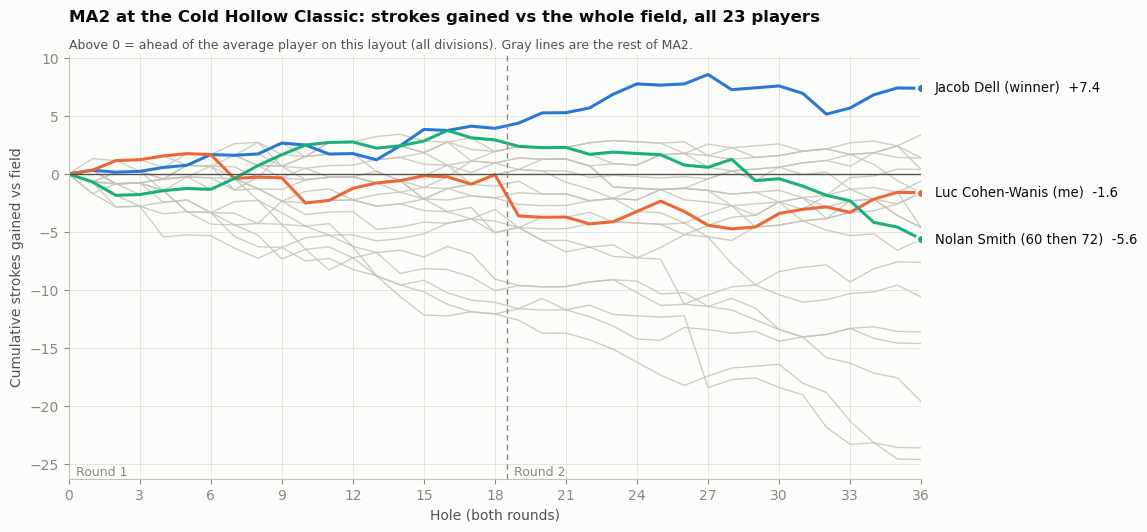

In [133]:
## Strokes gained: the race through 36 holes
# Cumulative strokes gained vs the whole field on this layout, hole by hole across both rounds
STARS = {'Jacob Dell': 'winner', 'Luc Cohen-Wanis': 'me', 'Nolan Smith': '60 then 72'}

worm = (div_df.sort_values('hole_seq')
        .assign(cum_sg=lambda d: d.groupby('player_name')['strokes_gained'].cumsum())
        .pivot(index='hole_seq', columns='player_name', values='cum_sg'))
worm.loc[0] = 0  # everyone starts at 0
worm = worm.sort_index()

fig, ax = plt.subplots(figsize=(11, 5.5))
for name in worm.columns.difference(list(STARS)):
    ax.plot(worm.index, worm[name], color='#c3c2b7', linewidth=1, alpha=0.8)
for (name, note), color in zip(STARS.items(), HIGHLIGHT):
    ax.plot(worm.index, worm[name], color=color, linewidth=2.2)
    ax.plot(36, worm.loc[36, name], 'o', color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f'{name} ({note})  {worm.loc[36, name]:+.1f}', (36, worm.loc[36, name]),
                xytext=(10, 0), textcoords='offset points', va='center', color=INK, fontsize=9.5)

ax.axhline(0, color=INK_2, linewidth=1)
ax.axvline(18.5, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(18.8, ax.get_ylim()[0], 'Round 2', color=MUTED, va='bottom', fontsize=9)
ax.text(0.3, ax.get_ylim()[0], 'Round 1', color=MUTED, va='bottom', fontsize=9)
ax.set_xlim(0, 36)
ax.set_xticks(range(0, 37, 3))
ax.set_xlabel('Hole (both rounds)')
ax.set_ylabel('Cumulative strokes gained vs field')
ax.set_title(f'{DIVISION} at the Cold Hollow Classic: strokes gained vs the whole field, all {len(worm.columns)} players', pad=24)
ax.text(0, 1.015, 'Above 0 = ahead of the average player on this layout (all divisions). Gray lines are the rest of MA2.',
        transform=ax.transAxes, color=INK_2, fontsize=9)
# plt.savefig(FIGURES_DIR / f'event_{EVENT_ID}_layout_{LAYOUT_ID}_{DIVISION}_strokes_gained.pdf', dpi=300, bbox_inches='tight')
plt.show()

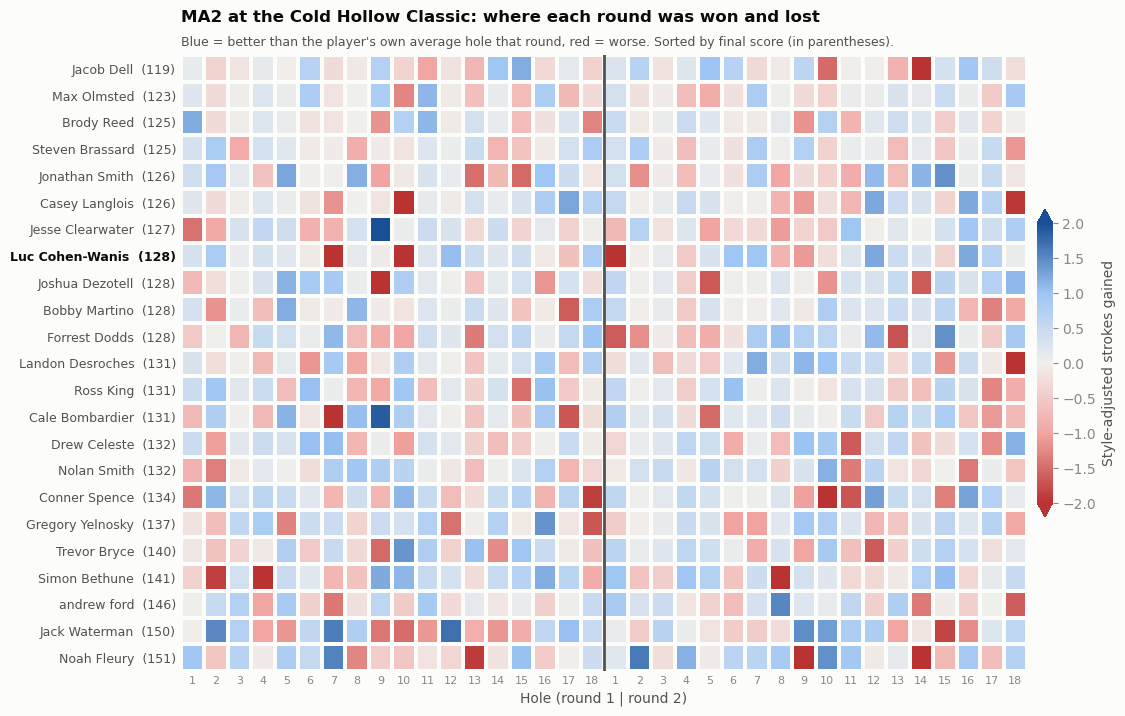

In [134]:
## Style-adjusted strokes gained: where each player's round went up and down
# Each cell is the hole's strokes gained minus the player's own average for that round,
# so every row-half sums to 0 and only the shape of the round is left
heat = div_df.pivot(index='player_name', columns='hole_seq', values='sg_style_adj').loc[standings.index]

fig, ax = plt.subplots(figsize=(13, 8))
lim = 2
mesh = ax.pcolormesh(heat.columns, range(len(heat)), heat.values, cmap=SG_CMAP, vmin=-lim, vmax=lim,
                     edgecolors=SURFACE, linewidth=1.5, shading='nearest')
ax.grid(False)
ax.invert_yaxis()
ax.set_yticks(range(len(heat)))
ax.set_yticklabels([f'{name}  ({standings[name]})' for name in heat.index], fontsize=9, color=INK_2)
for label in ax.get_yticklabels():
    if label.get_text().startswith('Luc Cohen-Wanis'):
        label.set_fontweight('bold'); label.set_color(INK)
ax.set_xticks(range(1, 37))
ax.set_xticklabels([str((h - 1) % 18 + 1) for h in range(1, 37)], fontsize=8)
ax.axvline(18.5, color=INK_2, linewidth=2)
ax.set_xlabel('Hole (round 1 | round 2)')
ax.tick_params(length=0)
for side in ['left', 'bottom']:
    ax.spines[side].set_visible(False)

cbar = fig.colorbar(mesh, ax=ax, shrink=0.5, pad=0.01, extend='both')
cbar.set_label('Style-adjusted strokes gained', color=INK_2)
cbar.outline.set_visible(False)
ax.set_title(f'{DIVISION} at the Cold Hollow Classic: where each round was won and lost', pad=24)
ax.text(0, 1.015, 'Blue = better than the player\'s own average hole that round, red = worse. Sorted by final score (in parentheses).',
        transform=ax.transAxes, color=INK_2, fontsize=9)
# plt.savefig(FIGURES_DIR / f'event_{EVENT_ID}_layout_{LAYOUT_ID}_{DIVISION}_sg_style_adj.pdf', dpi=300, bbox_inches='tight')
plt.show()

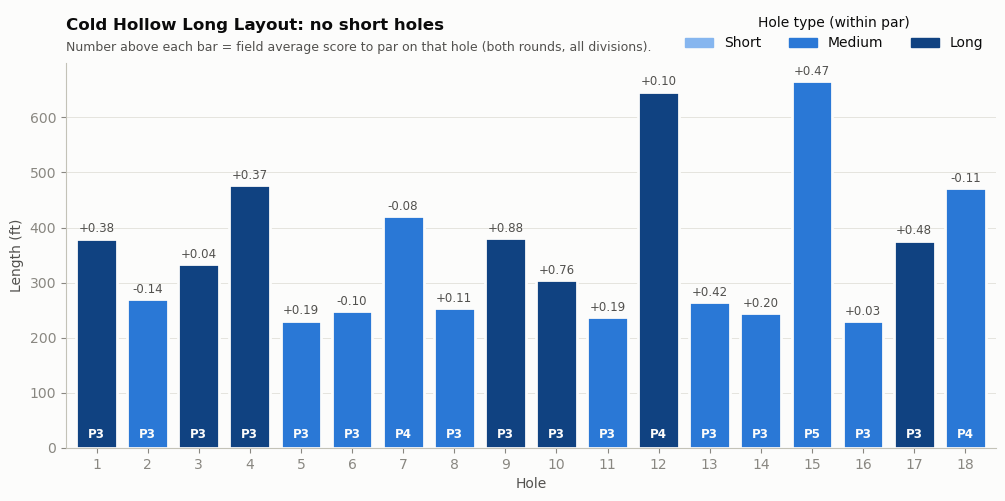

In [135]:
## Hole types: the course card
# Each bar is a hole's length, colored by its type within its par; the label above is how the field scored it
card = (event_df.groupby('hole')
        .agg(par=('par', 'first'), length_ft=('length_ft', 'first'), hole_type=('hole_type', 'first'),
             field_to_par=('score_to_par', 'mean')))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(card.index, card['length_ft'], width=0.8, color=card['hole_type'].astype(str).map(HOLE_TYPE_COLORS),
       edgecolor=SURFACE, linewidth=2)
for hole, row in card.iterrows():
    ax.text(hole, row['length_ft'] + 12, f'{row.field_to_par:+.2f}', ha='center', fontsize=8.5, color=INK_2)
    ax.text(hole, 18, f'P{row.par}', ha='center', fontsize=8.5, color=SURFACE, fontweight='bold')
ax.set_xticks(card.index)
ax.set_xlim(0.4, 18.6)
ax.set_xlabel('Hole')
ax.set_ylabel('Length (ft)')
ax.grid(axis='x', visible=False)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in HOLE_TYPE_COLORS.values()]
ax.legend(handles, [t.title() for t in HOLE_TYPE_COLORS], title='Hole type (within par)', frameon=False,
          loc='lower right', ncols=3, bbox_to_anchor=(1, 1.0))
ax.set_title('Cold Hollow Long Layout: no short holes', pad=24)
ax.text(0, 1.03, 'Number above each bar = field average score to par on that hole (both rounds, all divisions).',
        transform=ax.transAxes, color=INK_2, fontsize=9)
# plt.savefig(FIGURES_DIR / f'event_{EVENT_ID}_layout_{LAYOUT_ID}_hole_types.pdf', dpi=300, bbox_inches='tight')
plt.show()

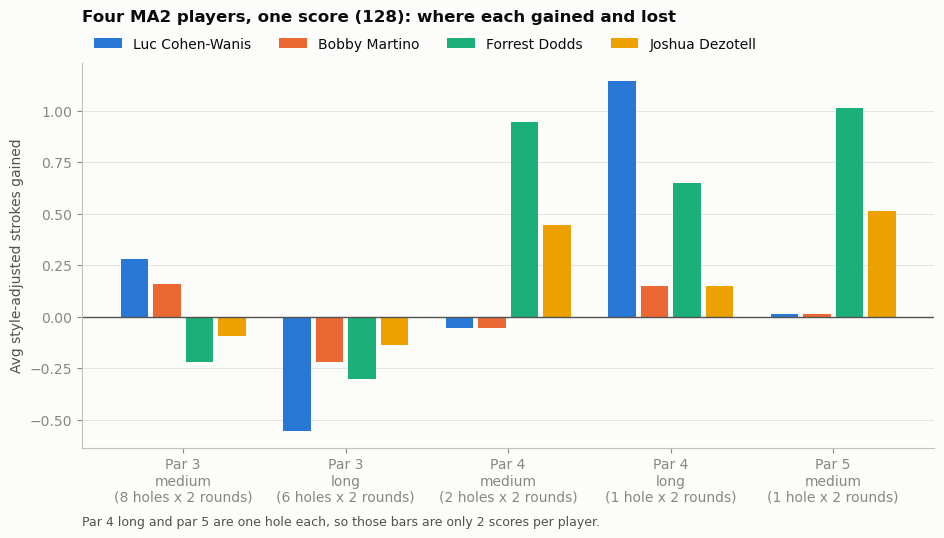

In [136]:
## Same score, different styles: the four MA2 players who shot 128
# Average style-adjusted strokes gained on each par x hole type at this course
tied = standings[standings == 128].index
profile = (div_df[div_df['player_name'].isin(tied)]
           .assign(hole_kind=lambda d: 'Par ' + d['par'].astype(str) + '\n' + d['hole_type'].astype(str))
           .groupby(['hole_kind', 'player_name'])['sg_style_adj'].mean()
           .unstack())
holes_per_kind = card.assign(hole_kind=lambda d: 'Par ' + d['par'].astype(str) + '\n' + d['hole_type'].astype(str)).hole_kind.value_counts()
order = [f'Par {par}\n{t}' for par in (3, 4, 5) for t in ('short', 'medium', 'long')]
profile = profile.loc[[k for k in order if k in profile.index]]
players = ['Luc Cohen-Wanis'] + [p for p in profile.columns if p != 'Luc Cohen-Wanis']
colors = HIGHLIGHT + ['#eda100']

fig, ax = plt.subplots(figsize=(11, 5))
width = 0.2
x = np.arange(len(profile))
for i, (player, color) in enumerate(zip(players, colors)):
    ax.bar(x + (i - 1.5) * width, profile[player], width=width - 0.03, color=color, label=player)
ax.axhline(0, color=INK_2, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels([f'{k}\n({holes_per_kind[k]} hole{"s" if holes_per_kind[k] > 1 else ""} x 2 rounds)' for k in profile.index])
ax.set_ylabel('Avg style-adjusted strokes gained')
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, ncols=4, loc='upper left', bbox_to_anchor=(0, 1.1))
ax.set_title('Four MA2 players, one score (128): where each gained and lost', pad=30)
ax.text(0, -0.2, 'Par 4 long and par 5 are one hole each, so those bars are only 2 scores per player.', transform=ax.transAxes, color=INK_2, fontsize=9)
# plt.savefig(FIGURES_DIR / f'event_{EVENT_ID}_layout_{LAYOUT_ID}_{DIVISION}_tied_128.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Player Style Profiles

From the proposal: for each player, a style profile of (1) strokes gained by hole type, (2) their mix of birdies, pars, bogeys and worse, and (3) how much they vary from round to round.

Choices:
- **Window:** 2020-2023 events only, since 2019 has sparse hole-by-hole coverage, styles are assigned there, and 2024-2026 is held out for the style x hole type model.
- **Players:** training data only (a PDGA number and an event-time `event_rating`). Unrated players still count toward strokes gained but do not enter profiles.
- **Minimum data:** at least 2 events, 4 usable rated rounds, and 72 usable holes per player. Two events provide repeated observations beyond one tournament while retaining enough players for exploratory clustering.
- **Hole types** are pooled across par (short / medium / long), because par 5s are too rare to split three ways (median 2 par 5 holes per player per type). Par 3 vs par 4+ is a separate feature.
- **Shrinkage:** hole-type averages are pulled toward 0 as if each player also had 50 holes at 0, so a few holes can't make a player look like a specialist.
- **Skill adjustment:** `event_rating` is retained as the event-time skill reference. The derived `*_vs_skill` features are residuals from `add_skill_adjusted`, which currently uses strokes gained per 18 as a performance-based skill measure.

In [146]:
## Player style profiles
# Styles are assigned on 2020-2023 events; 2024-2026 is held out for the style x hole type model.
# Players need at least two events, four usable rated rounds, and 72 usable holes.
PROFILE_YEARS = range(2020, 2024)
MIN_EVENTS = 2
MIN_ROUNDS = 2 * MIN_EVENTS
MIN_HOLES = MIN_ROUNDS * 18
SHRINK_HOLES = 50    # hole-type averages are pulled toward 0 as if the player also had 50 holes at exactly 0

def build_profiles(df, min_events=MIN_EVENTS, min_rounds=MIN_ROUNDS, min_holes=MIN_HOLES, shrink_holes=SHRINK_HOLES):
    """One row per player: skill reference, style features, score mix, and consistency."""
    # Training data only: drops rounds by players with no PDGA number or no event-time rating.
    df = df[df['in_training']]
    player_rounds = df.groupby(['player_key', 'event_id', 'round']).agg(
        round_sg_18=('round_sg_avg', 'first'), rating=('event_rating', 'first'))
    player_rounds['round_sg_18'] *= 18  # strokes gained per 18 holes, so 9- and 24-hole rounds compare
    player_summary = player_rounds.groupby('player_key').size().rename('n_rounds').to_frame()
    player_summary['n_events'] = df.groupby('player_key')['event_id'].nunique()
    player_summary['n_holes'] = df.groupby('player_key').size()
    eligible_players = player_summary.index
    keep = player_summary.index[
        (player_summary['n_events'] >= min_events)
        & (player_summary['n_rounds'] >= min_rounds)
        & (player_summary['n_holes'] >= min_holes)
    ]
    df = df[df['player_key'].isin(keep)]
    player_rounds = player_rounds[player_rounds.index.get_level_values('player_key').isin(keep)]
    players = df.groupby('player_key')

    profiles = pd.DataFrame({
        # Event-time rating is retained as the external skill reference, not a style feature.
        'n_events': player_summary.loc[keep, 'n_events'],
        'n_rounds': player_summary.loc[keep, 'n_rounds'],
        'n_holes': player_summary.loc[keep, 'n_holes'],
        'rating': player_rounds.groupby('player_key')['rating'].median(),
        'sg_per_18': players['strokes_gained'].mean() * 18,
    })

    # 1. Style-adjusted strokes gained per hole by hole type, shrunk toward 0 when a player has few holes of that type.
    by_type = df.groupby(['player_key', 'hole_type'], observed=True)['sg_style_adj'].agg(['sum', 'size'])
    shrunk = (by_type['sum'] / (by_type['size'] + shrink_holes)).unstack().fillna(0)  # no holes of a type = fully shrunk to 0
    for hole_type in ['short', 'medium', 'long']:
        profiles[f'sg_{hole_type}'] = shrunk[hole_type]
    # Par 3s vs par 4s and 5s (style-adjusted SG sums to 0 per round, so one number covers both).
    by_par = df.assign(par_group=np.where(df['par'] == 3, 'par3', 'par4plus')).groupby(['player_key', 'par_group'])['sg_style_adj'].agg(['sum', 'size'])
    shrunk_par = (by_par['sum'] / (by_par['size'] + shrink_holes)).unstack().fillna(0)
    profiles['sg_par3_minus_par4plus'] = shrunk_par['par3'] - shrunk_par['par4plus']

    # 2. Score mix: share of holes at each score to par.
    to_par = df['score_to_par']
    mix = pd.DataFrame({
        'pct_birdie_or_better': to_par <= -1, 'pct_par': to_par == 0,
        'pct_bogey': to_par == 1, 'pct_double_or_worse': to_par >= 2,
    }).groupby(df['player_key']).mean()
    profiles = profiles.join(mix)

    # 3. Consistency: hole-to-hole swings within a round, and round-to-round swings.
    profiles['hole_volatility'] = players['sg_style_adj'].std()
    profiles['round_sd_18'] = player_rounds.groupby('player_key')['round_sg_18'].std()
    return profiles, player_summary, eligible_players, keep

profile_df = features_df[features_df['year'].isin(PROFILE_YEARS)]
profiles, profile_counts, eligible_players, retained_players = build_profiles(profile_df)
excluded_players = eligible_players.difference(retained_players)
print(f'Eligible rated players: {len(eligible_players):,}')
print(f'Retained players: {len(retained_players):,} ({len(retained_players) / len(eligible_players):.1%})')
print(f'Excluded players: {len(excluded_players):,}')
print(f'Requirements: {MIN_EVENTS} events, {MIN_ROUNDS} usable rated rounds, and {MIN_HOLES} usable holes')
print(f"Retained events: median {profiles['n_events'].median():,.0f}; range {profiles['n_events'].min():,.0f}-{profiles['n_events'].max():,.0f}")
print(f"Retained holes: median {profiles['n_holes'].median():,.0f}; range {profiles['n_holes'].min():,.0f}-{profiles['n_holes'].max():,.0f}")
print(f"Retained rounds: median {profiles['n_rounds'].median():,.0f}; range {profiles['n_rounds'].min():,.0f}-{profiles['n_rounds'].max():,.0f}")
profiles.describe().T.round(3)

Eligible rated players: 1,055
Retained players: 604 (57.3%)
Excluded players: 451
Requirements: 2 events, 4 usable rated rounds, and 72 usable holes
Retained events: median 4; range 2-46
Retained holes: median 171; range 72-1,710
Retained rounds: median 10; range 4-95


,count,mean,std,min,25%,50%,75%,max
n_events,604.0,7.578,7.852,2.000,2.000,4.000,9.000,46.000
n_rounds,604.0,16.159,16.008,4.000,6.000,9.500,20.000,95.000
n_holes,604.0,290.861,288.142,72.000,108.000,171.000,360.000,1710.000
rating,604.0,883.613,71.414,320.000,853.875,894.000,930.000,1018.000
sg_per_18,604.0,0.396,4.540,-30.802,-1.637,0.788,3.408,11.705
sg_short,604.0,-0.004,0.038,-0.133,-0.025,0.000,0.019,0.109
sg_medium,604.0,-0.001,0.039,-0.137,-0.026,-0.001,0.023,0.123
sg_long,604.0,0.000,0.038,-0.138,-0.021,0.001,0.023,0.133
sg_par3_minus_par4plus,604.0,0.001,0.095,-0.274,-0.064,-0.004,0.059,0.395
pct_birdie_or_better,604.0,0.154,0.072,0.000,0.106,0.148,0.201,0.417


In [147]:
## Skill-adjusted versions
# Most profile features still track skill: better players birdie more, blow up less, and gain more on
# harder holes (par 4s and 5s), since there are more strokes to gain there.
# Regress each on strokes gained per 18 (quadratic) and keep the residual: e.g. a positive
# pct_birdie_or_better_vs_skill means more birdies than players of the same skill
PROFILE_FEATURES = ['sg_short', 'sg_medium', 'sg_long', 'sg_par3_minus_par4plus',
                    'pct_birdie_or_better', 'pct_par', 'pct_bogey', 'pct_double_or_worse',
                    'hole_volatility', 'round_sd_18']
STYLE_FEATURES = [f'{col}_vs_skill' for col in PROFILE_FEATURES]

def add_skill_adjusted(profiles):
    profiles = profiles.copy()
    for col in PROFILE_FEATURES:
        fit = np.polyfit(profiles['sg_per_18'], profiles[col], deg=2)
        profiles[f'{col}_vs_skill'] = profiles[col] - np.polyval(fit, profiles['sg_per_18'])
    return profiles

profiles = add_skill_adjusted(profiles)
profiles[STYLE_FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
sg_short_vs_skill,604.0,0.0,0.036,-0.139,-0.021,0.004,0.022,0.107
sg_medium_vs_skill,604.0,0.0,0.039,-0.137,-0.026,0.000,0.025,0.123
sg_long_vs_skill,604.0,0.0,0.037,-0.133,-0.022,-0.000,0.022,0.129
sg_par3_minus_par4plus_vs_skill,604.0,-0.0,0.075,-0.289,-0.048,0.005,0.054,0.211
pct_birdie_or_better_vs_skill,604.0,-0.0,0.042,-0.177,-0.027,0.002,0.027,0.174
pct_par_vs_skill,604.0,-0.0,0.055,-0.203,-0.031,0.001,0.036,0.239
pct_bogey_vs_skill,604.0,-0.0,0.043,-0.136,-0.027,-0.003,0.027,0.156
pct_double_or_worse_vs_skill,604.0,-0.0,0.035,-0.093,-0.024,-0.005,0.020,0.170
hole_volatility_vs_skill,604.0,-0.0,0.096,-0.242,-0.063,-0.011,0.049,0.501
round_sd_18_vs_skill,604.0,-0.0,2.217,-5.264,-1.146,-0.263,0.776,18.976


In [148]:
## Which profile features are stable enough to cluster on?
# Split each player's events into two halves (alternating events, so both halves span the same seasons),
# build a profile from each half, and correlate. Spearman because a few blow-up holes create outliers.
# Spearman-Brown projects the half-length correlation up to the full data.
events_order = (profile_df[['player_key', 'event_id']].drop_duplicates()
                .assign(half=lambda d: d.groupby('player_key').cumcount() % 2))
halves = profile_df.merge(events_order, on=['player_key', 'event_id'])
half_profiles = [add_skill_adjusted(build_profiles(
    halves[halves['half'] == h], min_events=MIN_EVENTS // 2, min_rounds=MIN_ROUNDS // 2, min_holes=MIN_HOLES // 2
)[0]) for h in (0, 1)]
both = half_profiles[0].index.intersection(half_profiles[1].index)

reliability = pd.DataFrame({
    col: {
        'split_half_r': half_profiles[0].loc[both, col].corr(half_profiles[1].loc[both, col], method='spearman'),
        'corr_with_skill': profiles[col].corr(profiles['sg_per_18'], method='spearman'),
    }
    for col in ['sg_per_18'] + PROFILE_FEATURES + STYLE_FEATURES
}).T
reliability['reliability'] = 2 * reliability['split_half_r'] / (1 + reliability['split_half_r'])
reliability['is_style_feature'] = reliability.index.isin(STYLE_FEATURES)
print(f'{len(both)} players have {MIN_ROUNDS // 2}+ rounds and {MIN_HOLES // 2}+ holes in both halves')
reliability.round(2)

602 players have 2+ rounds and 36+ holes in both halves


,split_half_r,corr_with_skill,reliability,is_style_feature
sg_per_18,0.63,1.00,0.77,False
sg_short,0.11,-0.26,0.20,False
sg_medium,0.02,-0.03,0.03,False
sg_long,0.08,0.23,0.14,False
sg_par3_minus_par4plus,0.22,-0.57,0.36,False
pct_birdie_or_better,0.49,0.80,0.66,False
pct_par,0.28,0.43,0.44,False
pct_bogey,0.41,-0.75,0.58,False
pct_double_or_worse,0.27,-0.71,0.43,False
hole_volatility,0.24,-0.31,0.38,False


# First clustering

I cluster the skill-adjusted profile features (`STYLE_FEATURES`) after standardizing them so features with larger numeric scales do not dominate. I compare K-means and Gaussian mixture models for several cluster counts. Silhouette scores compare separation for both models; BIC is defined for the Gaussian mixtures and rewards fit while penalizing unnecessary components. The first clustering uses the Gaussian mixture with the lowest BIC, with silhouette and cluster sizes reported as checks.

,model,n_clusters,silhouette,bic
0,K-means,2,0.165,NaN
1,Gaussian mixture,2,0.158,8877.871
2,K-means,3,0.122,NaN
3,Gaussian mixture,3,0.145,8754.351
4,K-means,4,0.120,NaN
5,Gaussian mixture,4,0.104,8985.625
6,K-means,5,0.125,NaN
7,Gaussian mixture,5,0.033,9134.682
8,K-means,6,0.122,NaN
9,Gaussian mixture,6,-0.010,9376.205


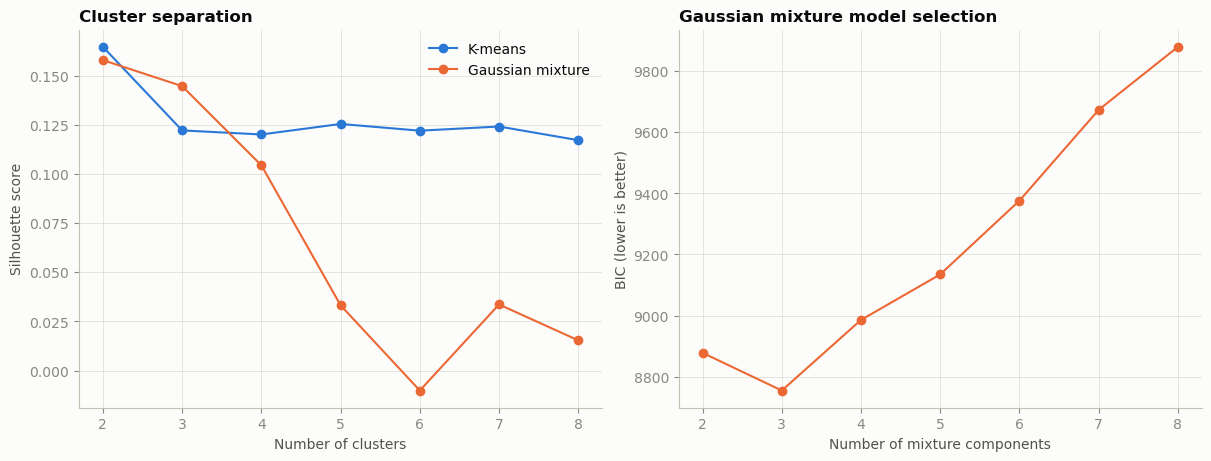

First clustering: Gaussian mixture with k=3
BIC: 8754.4; silhouette: 0.145
Cluster sizes:
cluster
0     56
1    375
2    173


In [149]:
## K-means and Gaussian mixture model sweep
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

CLUSTER_FEATURES = STYLE_FEATURES
cluster_profiles = profiles[CLUSTER_FEATURES].dropna().copy()
scaler = StandardScaler()
X_cluster = scaler.fit_transform(cluster_profiles)

CLUSTER_COUNTS = range(2, 9)
cluster_results = []
models = {}
for n_clusters in CLUSTER_COUNTS:
    kmeans = KMeans(n_clusters=n_clusters, n_init=50, random_state=0)
    kmeans_labels = kmeans.fit_predict(X_cluster)
    cluster_results.append({
        'model': 'K-means',
        'n_clusters': n_clusters,
        'silhouette': silhouette_score(X_cluster, kmeans_labels),
        'bic': float('nan'),
    })
    models[('K-means', n_clusters)] = (kmeans, kmeans_labels)

    mixture = GaussianMixture(
        n_components=n_clusters,
        covariance_type='full',
        n_init=10,
        reg_covar=1e-5,
        random_state=0,
    )
    mixture_labels = mixture.fit_predict(X_cluster)
    cluster_results.append({
        'model': 'Gaussian mixture',
        'n_clusters': n_clusters,
        'silhouette': silhouette_score(X_cluster, mixture_labels),
        'bic': mixture.bic(X_cluster),
    })
    models[('Gaussian mixture', n_clusters)] = (mixture, mixture_labels)

cluster_results = pd.DataFrame(cluster_results)
display(cluster_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for model_name, color in [('K-means', '#2a78d6'), ('Gaussian mixture', '#eb6834')]:
    subset = cluster_results[cluster_results['model'] == model_name]
    axes[0].plot(subset['n_clusters'], subset['silhouette'], marker='o', color=color, label=model_name)
axes[0].set(xlabel='Number of clusters', ylabel='Silhouette score', title='Cluster separation')
axes[0].set_xticks(list(CLUSTER_COUNTS))
axes[0].legend(frameon=False)

mixture_results = cluster_results[cluster_results['model'] == 'Gaussian mixture']
axes[1].plot(mixture_results['n_clusters'], mixture_results['bic'], marker='o', color='#eb6834')
axes[1].set(xlabel='Number of mixture components', ylabel='BIC (lower is better)', title='Gaussian mixture model selection')
axes[1].set_xticks(list(CLUSTER_COUNTS))
plt.show()

best_mixture_row = mixture_results.loc[mixture_results['bic'].idxmin()]
FIRST_MODEL = ('Gaussian mixture', int(best_mixture_row['n_clusters']))
first_model, first_labels = models[FIRST_MODEL]
cluster_profiles['cluster'] = first_labels
profiles.loc[cluster_profiles.index, 'cluster'] = first_labels
cluster_sizes = cluster_profiles['cluster'].value_counts().sort_index()
print(f'First clustering: {FIRST_MODEL[0]} with k={FIRST_MODEL[1]}')
print(f"BIC: {best_mixture_row['bic']:.1f}; silhouette: {mixture_results.loc[mixture_results['n_clusters'] == FIRST_MODEL[1], 'silhouette'].iloc[0]:.3f}")
print('Cluster sizes:')
print(cluster_sizes.to_string())

In [150]:
## Interpreting the first clusters
# Compare the clusters with overall performance and variance before assigning archetype names.
# The raw skill measures are not clustering inputs; they help test whether clusters are mostly skill.
cluster_profiles['rating'] = profiles.loc[cluster_profiles.index, 'rating']
cluster_profiles['sg_per_18'] = profiles.loc[cluster_profiles.index, 'sg_per_18']
cluster_profiles['round_sd_18'] = profiles.loc[cluster_profiles.index, 'round_sd_18']
cluster_profiles['hole_volatility'] = profiles.loc[cluster_profiles.index, 'hole_volatility']

cluster_summary = (cluster_profiles.groupby('cluster')
                   .agg(n_players=('sg_per_18', 'size'),
                        median_rating=('rating', 'median'),
                        mean_sg_per_18=('sg_per_18', 'mean'),
                        median_sg_per_18=('sg_per_18', 'median'),
                        median_round_sd_18=('round_sd_18', 'median'),
                        median_hole_volatility=('hole_volatility', 'median'))
                   .sort_values('mean_sg_per_18'))
display(cluster_summary.round(3))

# Standardized centroids show what differs after the skill adjustment used for clustering.
centroids = (cluster_profiles.groupby('cluster')[CLUSTER_FEATURES].mean()
             .pipe(lambda d: (d - cluster_profiles[CLUSTER_FEATURES].mean())
                   / cluster_profiles[CLUSTER_FEATURES].std()))
display(centroids.round(2))

print('Cluster correlations with raw performance:')
print(cluster_profiles.groupby('cluster')[['rating', 'sg_per_18', 'round_sd_18', 'hole_volatility']]
      .mean().corr().round(2))

for cluster, row in cluster_summary.iterrows():
    direction = 'lower' if row['mean_sg_per_18'] < cluster_summary['mean_sg_per_18'].median() else 'higher'
    variance = 'more variable' if row['median_round_sd_18'] > cluster_summary['median_round_sd_18'].median() else 'more consistent'
    print(f"Cluster {cluster}: {direction}-performing, {variance}; "
          f"median rating {row['median_rating']:.0f}, median SG/18 {row['median_sg_per_18']:.2f}.")

,n_players,median_rating,mean_sg_per_18,median_sg_per_18,median_round_sd_18,median_hole_volatility
cluster,,,,,,
0,56,821.0,-2.730,-1.541,6.198,0.742
2,173,925.0,0.641,0.872,4.439,0.835
1,375,892.0,0.749,0.929,3.956,0.729


,sg_short_vs_skill,sg_medium_vs_skill,sg_long_vs_skill,sg_par3_minus_par4plus_vs_skill,pct_birdie_or_better_vs_skill,pct_par_vs_skill,pct_bogey_vs_skill,pct_double_or_worse_vs_skill,hole_volatility_vs_skill,round_sd_18_vs_skill
cluster,,,,,,,,,,
0,0.31,-0.07,-0.37,-0.24,0.42,0.11,-0.20,-0.42,-0.29,1.09
1,-0.17,0.10,0.07,0.07,0.16,0.32,-0.24,-0.40,-0.33,-0.20
2,0.28,-0.19,-0.04,-0.07,-0.49,-0.72,0.58,1.01,0.80,0.07


Cluster correlations with raw performance:
                 rating  sg_per_18  round_sd_18  hole_volatility
rating             1.00       0.98        -0.95             0.38
sg_per_18          0.98       1.00        -0.99             0.20
round_sd_18       -0.95      -0.99         1.00            -0.06
hole_volatility    0.38       0.20        -0.06             1.00
Cluster 0: lower-performing, more variable; median rating 821, median SG/18 -1.54.
Cluster 2: higher-performing, more consistent; median rating 925, median SG/18 0.87.
Cluster 1: higher-performing, more consistent; median rating 892, median SG/18 0.93.


### Preliminary interpretation

- **Cluster 0: lower-skill, high round-variance players.** These 56 players have median rating 821 and median SG/18 of -1.54. Their round-to-round SD is highest (6.20), but their hole volatility is below average. Their adjusted profile suggests relatively strong short-hole and birdie rates but losses on long holes; the main signal is inconsistent overall rounds rather than a clean hole-by-hole specialty.
- **Cluster 1: steady, par-oriented players.** These 375 players have median rating 892 and median SG/18 of 0.93. They have the lowest round SD (3.96), above-average adjusted par rate, and below-average bogey, double-bogey, and hole-volatility measures. This is the clearest consistency archetype.
- **Cluster 2: higher-rated, volatile score-mix players.** These 173 players have the highest median rating (925) but nearly the same median SG/18 as cluster 1. They have much higher hole volatility, lower adjusted birdie and par rates, and higher bogey/double-bogey rates. This looks more like a volatile scoring pattern than a distinct course-type preference.

Overall, the first clustering appears to reflect a strong skill gradient plus two kinds of variance: round-to-round inconsistency among lower-performing players and hole-level score volatility among higher-rated players. The evidence for three clean, independent playing-style archetypes is weak; cluster 1 versus cluster 2 is the more promising style comparison because their overall performance is similar while their score mix and variance differ.

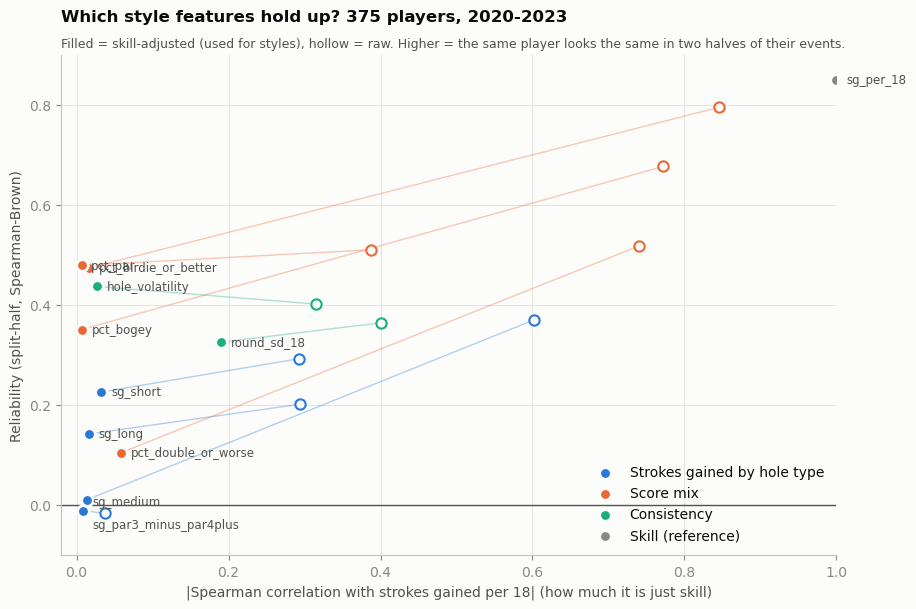

In [140]:
## Style features: how stable vs how much they just track skill
# Good style features sit top-left: stable from one half of a player's events to the other, but not just skill
# Filled points are the skill-adjusted features used for styles; hollow points are the raw versions
plot_df = reliability.loc[STYLE_FEATURES + PROFILE_FEATURES + ['sg_per_18']].copy()
plot_df['adjusted'] = plot_df.index.str.endswith('_vs_skill') | (plot_df.index == 'sg_per_18')
plot_df['label'] = plot_df.index.str.removesuffix('_vs_skill')
plot_df.index = plot_df['label'].where(plot_df['adjusted'], plot_df['label'] + ' (raw)')
plot_df['group'] = np.select(
    [plot_df.index.str.startswith('sg_') & (plot_df.index != 'sg_per_18'), plot_df.index.str.startswith('pct_'), plot_df.index == 'sg_per_18'],
    ['Strokes gained by hole type', 'Score mix', 'Skill (reference)'], 'Consistency')
group_colors = {'Strokes gained by hole type': HIGHLIGHT[0], 'Score mix': HIGHLIGHT[1],
                'Consistency': HIGHLIGHT[2], 'Skill (reference)': MUTED}

# Label offsets (points) for features that land on top of each other near the origin
label_nudge = {'sg_medium': (7, 6), 'sg_par3_minus_par4plus': (4, -18), 'pct_double_or_worse': (7, 0)}

fig, ax = plt.subplots(figsize=(10, 6.5))
for group, color in group_colors.items():
    pts = plot_df[plot_df['group'] == group]
    raw, adj = pts[~pts['adjusted']], pts[pts['adjusted']]
    # Thin connector from each raw feature to its skill-adjusted version
    for label, row in adj.iterrows():
        if label + ' (raw)' in raw.index:
            r = raw.loc[label + ' (raw)']
            ax.plot([abs(r['corr_with_skill']), abs(row['corr_with_skill'])], [r['reliability'], row['reliability']],
                    color=color, linewidth=1, alpha=0.35, zorder=2)
    ax.scatter(raw['corr_with_skill'].abs(), raw['reliability'], s=55, facecolor=SURFACE, edgecolor=color, linewidth=1.5, zorder=3)
    ax.scatter(adj['corr_with_skill'].abs(), adj['reliability'], s=70, color=color, label=group,
               edgecolor=SURFACE, linewidth=2, zorder=3)
    for name, row in adj.iterrows():
        ax.annotate(name, (abs(row['corr_with_skill']), row['reliability']),
                    xytext=label_nudge.get(name, (7, 0)), textcoords='offset points', va='center', fontsize=8.5, color=INK_2)
ax.axhline(0, color=INK_2, linewidth=1)
ax.set_ylim(-0.1, 0.9)
ax.set_xlim(-0.02, 1.0)
ax.set_xlabel('|Spearman correlation with strokes gained per 18| (how much it is just skill)')
ax.set_ylabel('Reliability (split-half, Spearman-Brown)')
ax.legend(frameon=False, loc='lower right')
ax.set_title(f'Which style features hold up? {len(profiles)} players, {PROFILE_YEARS.start}-{PROFILE_YEARS.stop - 1}', pad=24)
ax.text(0, 1.015, 'Filled = skill-adjusted (used for styles), hollow = raw. Higher = the same player looks the same in two halves of their events.',
        transform=ax.transAxes, color=INK_2, fontsize=9)
plt.show()

**What the reliability check shows (2020-2023):**
- Raw score mix is very stable, but mostly because it's skill: birdie rate correlates 0.85 with strokes gained per 18.
- After removing skill, the stable style signal is in **score mix** (birdie rate 0.46, par rate 0.46, bogey rate 0.33) and **consistency** (hole volatility 0.43, round-to-round SD 0.33).
- **Strokes gained by hole type is weak.** Short holes are the only hole type with any signal (0.22). The raw par 3 vs par 4+ gap looked stable (0.39) but that was all skill: better players gain more on par 4s and 5s because there are more strokes to gain there. After skill adjustment it drops to 0.02.
- Double-bogey rate vs skill is ~0 (0.09): once skill is accounted for, blow-ups look like noise.

So clustering should probably lean on score mix and consistency. Hole-type preferences might still show up in the mixed model, which pools all 2024-2026 holes instead of one average per player.

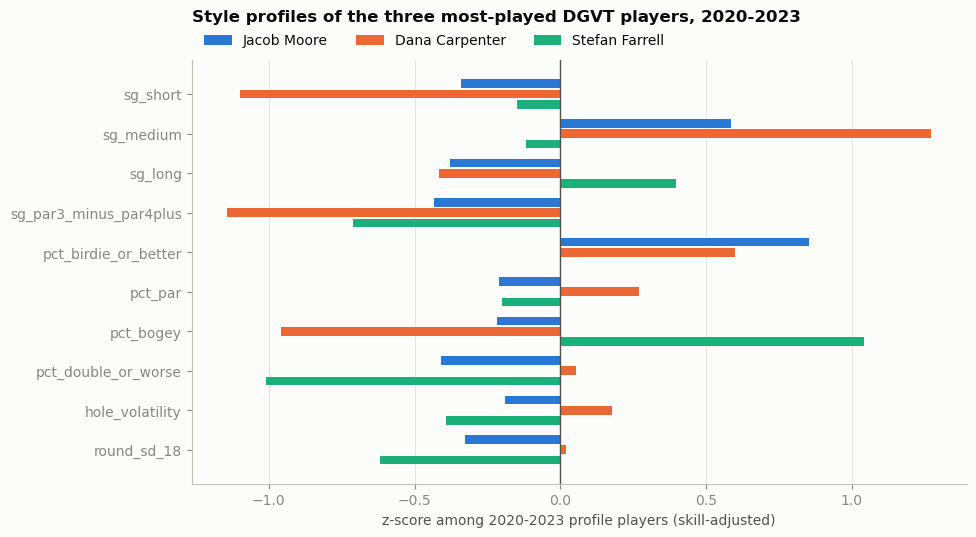

In [141]:
## Player cards: standardized style profile for a few players
# z-scores within the 2020-2023 players: 0 = typical, +1 = one SD above (e.g. gains more on short holes)
style_z = (profiles[STYLE_FEATURES] - profiles[STYLE_FEATURES].mean()) / profiles[STYLE_FEATURES].std()
name_lookup = rounds_df.dropna(subset=['player_name']).drop_duplicates('player_key').set_index('player_key')['player_name']
style_z.index = style_z.index.map(lambda key: name_lookup.get(key, key))

# The 3 most-played players in the profile window
featured = profiles.sort_values('n_rounds', ascending=False).head(3).index.map(lambda key: name_lookup.get(key, key))
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(STYLE_FEATURES))
height = 0.26
for i, (player, color) in enumerate(zip(featured, HIGHLIGHT)):
    ax.barh(y + (i - 1) * height, style_z.loc[player], height=height - 0.04, color=color, label=player)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels([f.removesuffix('_vs_skill') for f in STYLE_FEATURES])
ax.set_xlabel('z-score among 2020-2023 profile players (skill-adjusted)')
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.legend(frameon=False, ncols=3, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_title('Style profiles of the three most-played DGVT players, 2020-2023', pad=28)
plt.show()

# Ratings by Division

How skill is spread within and across divisions each season, using the PDGA rating at the time of each event (`event_rating`).

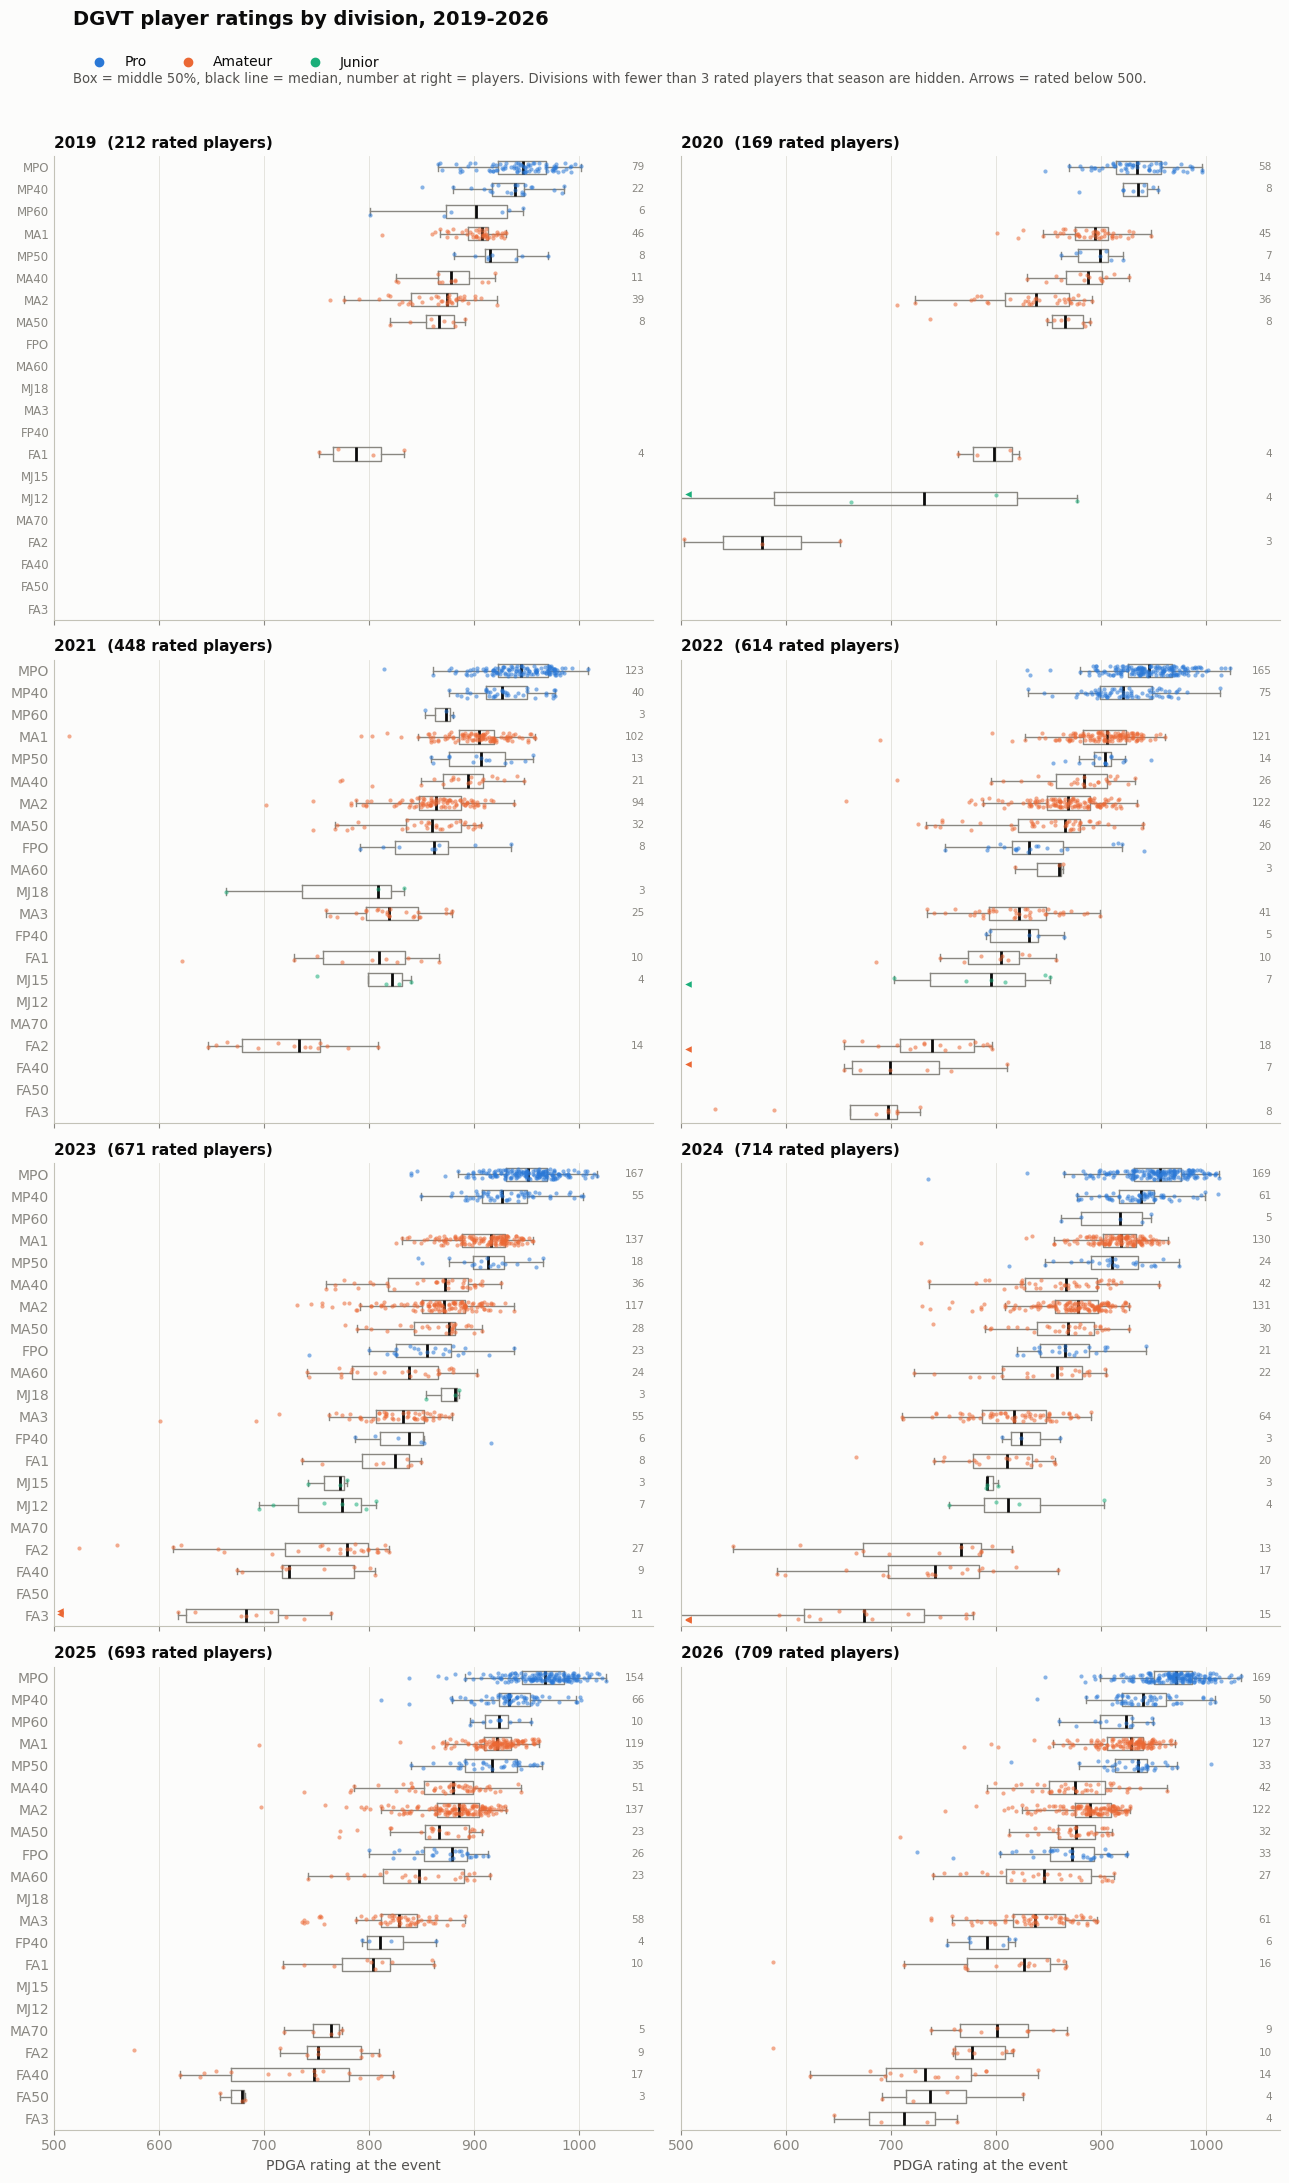

In [142]:
## Rating distribution by division, each season
# One point per player x division x season: the player's median event-time rating in that division that season,
# so players who entered many events don't count more than once. Unrated players are left out.
X_MIN = 500      # a few ratings (mostly juniors) are far lower; they're drawn as arrows at the left edge
MIN_PLAYERS = 3  # divisions with fewer rated players in a season are left out of that season's panel

season_ratings = (rounds_df[rounds_df['in_training']]
                  .drop_duplicates(['year', 'event_id', 'division', 'player_key'])
                  .groupby(['year', 'division', 'player_key'])['event_rating'].median()
                  .reset_index())
n_players = season_ratings.groupby(['year', 'division'])['player_key'].transform('size')
season_ratings = season_ratings[n_players >= MIN_PLAYERS]

# Same division order in every panel: highest median rating at the top
division_order = season_ratings.groupby('division')['event_rating'].median().sort_values(ascending=False).index
division_group = lambda d: 'Junior' if d[1] == 'J' else ('Pro' if d[1] == 'P' else 'Amateur')
group_colors = {'Pro': HIGHLIGHT[0], 'Amateur': HIGHLIGHT[1], 'Junior': HIGHLIGHT[2]}
years = sorted(season_ratings['year'].unique())
rng = np.random.default_rng(0)

fig, axes = plt.subplots(len(years) // 2, 2, figsize=(13, 22), sharex=True, sharey=True)
y_pos = {division: i for i, division in enumerate(division_order)}
for ax, year in zip(axes.flat, years):
    season = season_ratings[season_ratings['year'] == year]
    for division, players in season.groupby('division'):
        y = y_pos[division]
        color = group_colors[division_group(division)]
        ax.boxplot(players['event_rating'], positions=[y], vert=False, widths=0.6, showfliers=False,
                   medianprops=dict(color=INK, linewidth=2), boxprops=dict(color=MUTED, linewidth=1),
                   whiskerprops=dict(color=MUTED, linewidth=1), capprops=dict(color=MUTED, linewidth=1))
        jitter = y + rng.uniform(-0.22, 0.22, len(players))
        low = players['event_rating'].to_numpy() < X_MIN
        ax.scatter(players['event_rating'][~low], jitter[~low], s=9, color=color, alpha=0.55, linewidth=0, zorder=3)
        ax.scatter(np.full(low.sum(), X_MIN + 6), jitter[low], s=22, marker='<', color=color, linewidth=0, zorder=3)
        ax.text(1062, y, f'{len(players)}', va='center', ha='right', fontsize=7.5, color=MUTED)
    ax.set_title(f'{year}  ({season.player_key.nunique()} rated players)', fontsize=11)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)

axes[0, 0].set_yticks(range(len(division_order)))
axes[0, 0].set_yticklabels(division_order, fontsize=8.5)
axes[0, 0].set_ylim(len(division_order) - 0.5, -0.5)
axes[0, 0].set_xlim(X_MIN, 1070)
for ax in axes[-1]:
    ax.set_xlabel('PDGA rating at the event')
handles = [plt.Line2D([], [], marker='o', linestyle='', color=c, markersize=6) for c in group_colors.values()]
fig.legend(handles, group_colors.keys(), frameon=False, ncols=3, loc='upper left', bbox_to_anchor=(0.06, 0.975))
fig.suptitle('DGVT player ratings by division, 2019-2026', x=0.06, ha='left', y=0.99, fontweight='bold', fontsize=14)
fig.text(0.06, 0.962, f'Box = middle 50%, black line = median, number at right = players. Divisions with fewer than {MIN_PLAYERS} rated players that season are hidden. Arrows = rated below {X_MIN}.',
         color=INK_2, fontsize=9.5, va='top')
fig.tight_layout(rect=(0, 0, 1, 0.955))
plt.show()